In [1]:
import pandas as pd
import numpy as np

from sklearn.datasets import load_iris

# Load Iris Dataset
iris = load_iris()

# Convert dataset into DataFrame
df = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

df["target"] = iris.target

df["species"] = df["target"].map(
    dict(enumerate(iris.target_names))
)

print("Dataset Loaded Successfully!")
print("Dataset Shape:", df.shape)

display(df.head())

Dataset Loaded Successfully!
Dataset Shape: (150, 6)


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


In [2]:
X = df[iris.feature_names]
y = df["target"]

print("Input Features:")
print(list(X.columns))

print("\nInput Features Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nSpecies Distribution:")
print(df["species"].value_counts())

Input Features:
['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']

Input Features Shape: (150, 4)
Target Shape: (150,)

Species Distribution:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


In [3]:
print("Dataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nFeature Statistics:")
display(X.describe())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   target             150 non-null    int64  
 5   species            150 non-null    object 
dtypes: float64(4), int64(1), object(1)
memory usage: 7.2+ KB

Missing Values:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
target               0
species              0
dtype: int64

Duplicate Rows: 1

Feature Statistics:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


In [4]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("Training Labels:", y_train.shape)
print("Testing Labels:", y_test.shape)

Training Features: (120, 4)
Testing Features: (30, 4)
Training Labels: (120,)
Testing Labels: (30,)


In [5]:
from sklearn.tree import DecisionTreeClassifier

# Create Decision Tree Model
dt_model = DecisionTreeClassifier(random_state=42)

# Train Model
dt_model.fit(X_train, y_train)

print("Decision Tree Model Trained Successfully!")

Decision Tree Model Trained Successfully!


In [6]:
y_pred = dt_model.predict(X_test)

results = pd.DataFrame({
    "Actual": y_test,
    "Predicted": y_pred
})

results["Actual Species"] = results["Actual"].map(
    dict(enumerate(iris.target_names))
)

results["Predicted Species"] = results["Predicted"].map(
    dict(enumerate(iris.target_names))
)

display(results.head(10))

,Actual,Predicted,Actual Species,Predicted Species
38,0,0,setosa,setosa
127,2,2,virginica,virginica
57,1,1,versicolor,versicolor
93,1,1,versicolor,versicolor
42,0,0,setosa,setosa
56,1,1,versicolor,versicolor
22,0,0,setosa,setosa
20,0,0,setosa,setosa
147,2,2,virginica,virginica
84,1,1,versicolor,versicolor


In [7]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test, y_pred, average="weighted"
)

recall = recall_score(
    y_test, y_pred, average="weighted"
)

f1 = f1_score(
    y_test, y_pred, average="weighted"
)

cm = confusion_matrix(y_test, y_pred)

print("===== Decision Tree Evaluation =====")
print("Accuracy :", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall   :", round(recall, 4))
print("F1-Score :", round(f1, 4))

print("\nConfusion Matrix:")
print(cm)

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=iris.target_names
))

===== Decision Tree Evaluation =====
Accuracy : 0.9333
Precision: 0.9333
Recall   : 0.9333
F1-Score : 0.9333

Confusion Matrix:
[[10  0  0]
 [ 0  9  1]
 [ 0  1  9]]

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



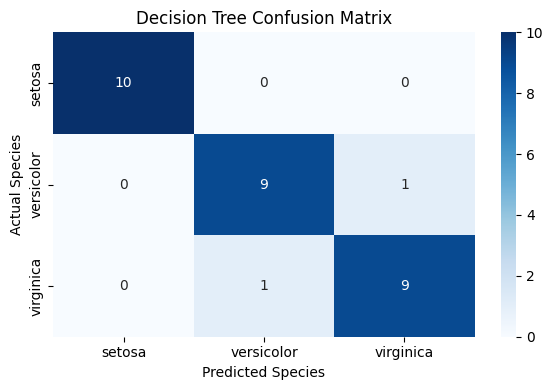

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=iris.target_names,
    yticklabels=iris.target_names
)

plt.title("Decision Tree Confusion Matrix")
plt.xlabel("Predicted Species")
plt.ylabel("Actual Species")
plt.tight_layout()
plt.show()

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import (
    load_breast_cancer,
    load_wine,
    load_diabetes
)

# Load Breast Cancer Dataset
cancer = load_breast_cancer()

cancer_df = pd.DataFrame(
    cancer.data,
    columns=cancer.feature_names
)
cancer_df["target"] = cancer.target

# Load Wine Dataset
wine = load_wine()

wine_df = pd.DataFrame(
    wine.data,
    columns=wine.feature_names
)
wine_df["target"] = wine.target

# Load Diabetes Dataset
diabetes = load_diabetes()

diabetes_df = pd.DataFrame(
    diabetes.data,
    columns=diabetes.feature_names
)
diabetes_df["target"] = diabetes.target

print("All Three Datasets Loaded Successfully!")

print("\nBreast Cancer Shape:", cancer_df.shape)
print("Wine Shape:", wine_df.shape)
print("Diabetes Shape:", diabetes_df.shape)

print("\nBreast Cancer Dataset:")
display(cancer_df.head())

print("\nWine Dataset:")
display(wine_df.head())

print("\nDiabetes Dataset:")
display(diabetes_df.head())

All Three Datasets Loaded Successfully!

Breast Cancer Shape: (569, 31)
Wine Shape: (178, 14)
Diabetes Shape: (442, 11)

Breast Cancer Dataset:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0



Wine Dataset:


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0



Diabetes Dataset:


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


In [10]:
# Breast Cancer
X_cancer = cancer_df.drop(columns=["target"])
y_cancer = cancer_df["target"]

# Wine
X_wine = wine_df.drop(columns=["target"])
y_wine = wine_df["target"]

# Diabetes
X_diabetes = diabetes_df.drop(columns=["target"])
y_diabetes = diabetes_df["target"]

print("BREAST CANCER")
print("Features:", X_cancer.shape)
print("Target:", y_cancer.shape)
print("Target Classes:", cancer.target_names)

print("\nWINE")
print("Features:", X_wine.shape)
print("Target:", y_wine.shape)
print("Target Classes:", wine.target_names)

print("\nDIABETES")
print("Features:", X_diabetes.shape)
print("Target:", y_diabetes.shape)
print("Target: Continuous disease progression measure")

BREAST CANCER
Features: (569, 30)
Target: (569,)
Target Classes: ['malignant' 'benign']

WINE
Features: (178, 13)
Target: (178,)
Target Classes: ['class_0' 'class_1' 'class_2']

DIABETES
Features: (442, 10)
Target: (442,)
Target: Continuous disease progression measure


In [11]:
datasets = {
    "Breast Cancer": cancer_df,
    "Wine": wine_df,
    "Diabetes": diabetes_df
}

for name, data in datasets.items():

    print("\n==============================")
    print(name, "DATASET")
    print("==============================")

    print("Shape:", data.shape)

    print("Missing Values:", data.isnull().sum().sum())

    print("Duplicate Rows:", data.duplicated().sum())

    print("\nStatistical Summary:")
    display(data.describe())


Breast Cancer DATASET
Shape: (569, 31)
Missing Values: 0
Duplicate Rows: 0

Statistical Summary:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946,0.627417
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061,0.483918
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040,0.000000
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460,0.000000
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040,1.000000
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080,1.000000
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500,1.000000



Wine DATASET
Shape: (178, 14)
Missing Values: 0
Duplicate Rows: 0

Statistical Summary:


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
count,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000
mean,13.000618,2.336348,2.366517,19.494944,99.741573,2.295112,2.029270,0.361854,1.590899,5.058090,0.957449,2.611685,746.893258,0.938202
std,0.811827,1.117146,0.274344,3.339564,14.282484,0.625851,0.998859,0.124453,0.572359,2.318286,0.228572,0.709990,314.907474,0.775035
min,11.030000,0.740000,1.360000,10.600000,70.000000,0.980000,0.340000,0.130000,0.410000,1.280000,0.480000,1.270000,278.000000,0.000000
25%,12.362500,1.602500,2.210000,17.200000,88.000000,1.742500,1.205000,0.270000,1.250000,3.220000,0.782500,1.937500,500.500000,0.000000
50%,13.050000,1.865000,2.360000,19.500000,98.000000,2.355000,2.135000,0.340000,1.555000,4.690000,0.965000,2.780000,673.500000,1.000000
75%,13.677500,3.082500,2.557500,21.500000,107.000000,2.800000,2.875000,0.437500,1.950000,6.200000,1.120000,3.170000,985.000000,2.000000
max,14.830000,5.800000,3.230000,30.000000,162.000000,3.880000,5.080000,0.660000,3.580000,13.000000,1.710000,4.000000,1680.000000,2.000000



Diabetes DATASET
Shape: (442, 11)
Missing Values: 0
Duplicate Rows: 0

Statistical Summary:


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
count,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,442.000000
mean,-2.511817e-19,1.230790e-17,-2.245564e-16,-4.797570e-17,-1.381499e-17,3.918434e-17,-5.777179e-18,-9.042540e-18,9.293722e-17,1.130318e-17,152.133484
std,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,77.093005
min,-1.072256e-01,-4.464164e-02,-9.027530e-02,-1.123988e-01,-1.267807e-01,-1.156131e-01,-1.023071e-01,-7.639450e-02,-1.260971e-01,-1.377672e-01,25.000000
25%,-3.729927e-02,-4.464164e-02,-3.422907e-02,-3.665608e-02,-3.424784e-02,-3.035840e-02,-3.511716e-02,-3.949338e-02,-3.324559e-02,-3.317903e-02,87.000000
50%,5.383060e-03,-4.464164e-02,-7.283766e-03,-5.670422e-03,-4.320866e-03,-3.819065e-03,-6.584468e-03,-2.592262e-03,-1.947171e-03,-1.077698e-03,140.500000
75%,3.807591e-02,5.068012e-02,3.124802e-02,3.564379e-02,2.835801e-02,2.984439e-02,2.931150e-02,3.430886e-02,3.243232e-02,2.791705e-02,211.500000
max,1.107267e-01,5.068012e-02,1.705552e-01,1.320436e-01,1.539137e-01,1.987880e-01,1.811791e-01,1.852344e-01,1.335973e-01,1.356118e-01,346.000000


In [12]:
from sklearn.model_selection import train_test_split

# Breast Cancer Split
Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    X_cancer,
    y_cancer,
    test_size=0.2,
    random_state=42,
    stratify=y_cancer
)

# Wine Split
Xw_train, Xw_test, yw_train, yw_test = train_test_split(
    X_wine,
    y_wine,
    test_size=0.2,
    random_state=42,
    stratify=y_wine
)

# Diabetes Split
Xd_train, Xd_test, yd_train, yd_test = train_test_split(
    X_diabetes,
    y_diabetes,
    test_size=0.2,
    random_state=42
)

print("BREAST CANCER")
print("Training:", Xc_train.shape)
print("Testing:", Xc_test.shape)

print("\nWINE")
print("Training:", Xw_train.shape)
print("Testing:", Xw_test.shape)

print("\nDIABETES")
print("Training:", Xd_train.shape)
print("Testing:", Xd_test.shape)

BREAST CANCER
Training: (455, 30)
Testing: (114, 30)

WINE
Training: (142, 13)
Testing: (36, 13)

DIABETES
Training: (353, 10)
Testing: (89, 10)


In [13]:
from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(random_state=42)

dt_model.fit(Xc_train, yc_train)

y_pred_cancer = dt_model.predict(Xc_test)

print("Decision Tree Model Trained Successfully!")
print("\nActual Values:")
print(yc_test.head(10).to_list())

print("\nPredicted Values:")
print(y_pred_cancer[:10])

Decision Tree Model Trained Successfully!

Actual Values:
[0, 1, 0, 1, 0, 1, 1, 0, 0, 0]

Predicted Values:
[0 1 0 1 0 1 1 0 0 0]


In [14]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_model.fit(Xw_train, yw_train)

y_pred_wine = rf_model.predict(Xw_test)

print("Random Forest Model Trained Successfully!")

print("\nActual Values:")
print(yw_test.head(10).to_list())

print("\nPredicted Values:")
print(y_pred_wine[:10])

Random Forest Model Trained Successfully!

Actual Values:
[0, 2, 0, 1, 1, 0, 0, 1, 1, 2]

Predicted Values:
[0 2 0 1 1 0 0 1 1 2]


In [15]:
from sklearn.ensemble import GradientBoostingRegressor

gb_model = GradientBoostingRegressor(
    n_estimators=100,
    random_state=42
)

gb_model.fit(Xd_train, yd_train)

y_pred_diabetes = gb_model.predict(Xd_test)

print("Gradient Boosting Model Trained Successfully!")

print("\nActual Values:")
print(yd_test.head(10).to_list())

print("\nPredicted Values:")
print(y_pred_diabetes[:10])

Gradient Boosting Model Trained Successfully!

Actual Values:
[219.0, 70.0, 202.0, 230.0, 111.0, 84.0, 242.0, 272.0, 94.0, 96.0]

Predicted Values:
[161.28890402 190.52483685 170.5310223  285.06072732 126.49996592
 134.88300076 256.88224286 222.7045274  165.78383004 148.87866257]


In [16]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Decision Tree Evaluation
dt_accuracy = accuracy_score(yc_test, y_pred_cancer)

dt_precision = precision_score(
    yc_test, y_pred_cancer, average="weighted"
)

dt_recall = recall_score(
    yc_test, y_pred_cancer, average="weighted"
)

dt_f1 = f1_score(
    yc_test, y_pred_cancer, average="weighted"
)

dt_cm = confusion_matrix(yc_test, y_pred_cancer)

print("===== DECISION TREE: BREAST CANCER =====")
print("Accuracy :", round(dt_accuracy, 4))
print("Precision:", round(dt_precision, 4))
print("Recall   :", round(dt_recall, 4))
print("F1-Score :", round(dt_f1, 4))

print("\nConfusion Matrix:")
print(dt_cm)

print("\nClassification Report:")
print(classification_report(
    yc_test,
    y_pred_cancer,
    target_names=cancer.target_names
))


# Random Forest Evaluation
rf_accuracy = accuracy_score(yw_test, y_pred_wine)

rf_precision = precision_score(
    yw_test, y_pred_wine, average="weighted"
)

rf_recall = recall_score(
    yw_test, y_pred_wine, average="weighted"
)

rf_f1 = f1_score(
    yw_test, y_pred_wine, average="weighted"
)

rf_cm = confusion_matrix(yw_test, y_pred_wine)

print("\n===== RANDOM FOREST: WINE =====")
print("Accuracy :", round(rf_accuracy, 4))
print("Precision:", round(rf_precision, 4))
print("Recall   :", round(rf_recall, 4))
print("F1-Score :", round(rf_f1, 4))

print("\nConfusion Matrix:")
print(rf_cm)

print("\nClassification Report:")
print(classification_report(
    yw_test,
    y_pred_wine,
    target_names=wine.target_names
))

===== DECISION TREE: BREAST CANCER =====
Accuracy : 0.9123
Precision: 0.9161
Recall   : 0.9123
F1-Score : 0.913

Confusion Matrix:
[[39  3]
 [ 7 65]]

Classification Report:
              precision    recall  f1-score   support

   malignant       0.85      0.93      0.89        42
      benign       0.96      0.90      0.93        72

    accuracy                           0.91       114
   macro avg       0.90      0.92      0.91       114
weighted avg       0.92      0.91      0.91       114


===== RANDOM FOREST: WINE =====
Accuracy : 1.0
Precision: 1.0
Recall   : 1.0
F1-Score : 1.0

Confusion Matrix:
[[12  0  0]
 [ 0 14  0]
 [ 0  0 10]]

Classification Report:
              precision    recall  f1-score   support

     class_0       1.00      1.00      1.00        12
     class_1       1.00      1.00      1.00        14
     class_2       1.00      1.00      1.00        10

    accuracy                           1.00        36
   macro avg       1.00      1.00      1.00        36


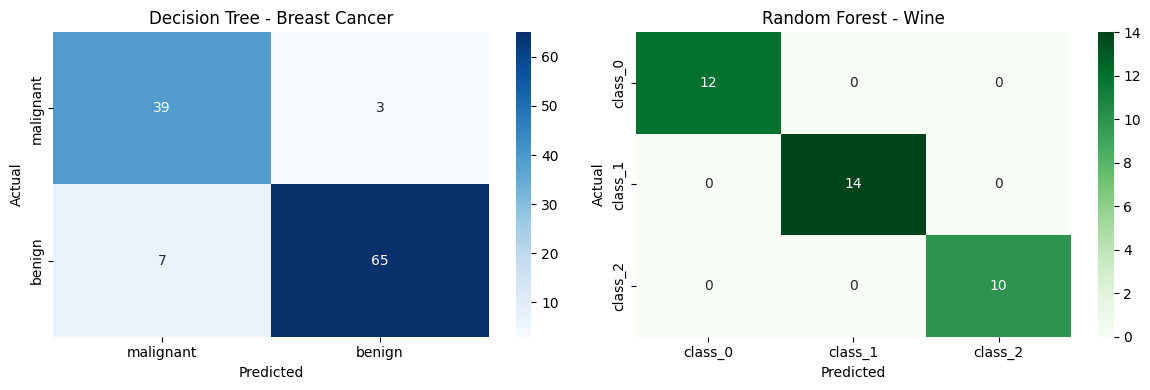

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.heatmap(
    dt_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=cancer.target_names,
    yticklabels=cancer.target_names,
    ax=axes[0]
)

axes[0].set_title("Decision Tree - Breast Cancer")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

sns.heatmap(
    rf_cm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=wine.target_names,
    yticklabels=wine.target_names,
    ax=axes[1]
)

axes[1].set_title("Random Forest - Wine")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

plt.tight_layout()
plt.show()

In [18]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

gb_mae = mean_absolute_error(
    yd_test, y_pred_diabetes
)

gb_mse = mean_squared_error(
    yd_test, y_pred_diabetes
)

gb_r2 = r2_score(
    yd_test, y_pred_diabetes
)

print("===== GRADIENT BOOSTING: DIABETES =====")
print("Mean Absolute Error (MAE):", round(gb_mae, 4))
print("Mean Squared Error (MSE):", round(gb_mse, 4))
print("R2 Score:", round(gb_r2, 4))

===== GRADIENT BOOSTING: DIABETES =====
Mean Absolute Error (MAE): 44.6033
Mean Squared Error (MSE): 2898.4367
R2 Score: 0.4529


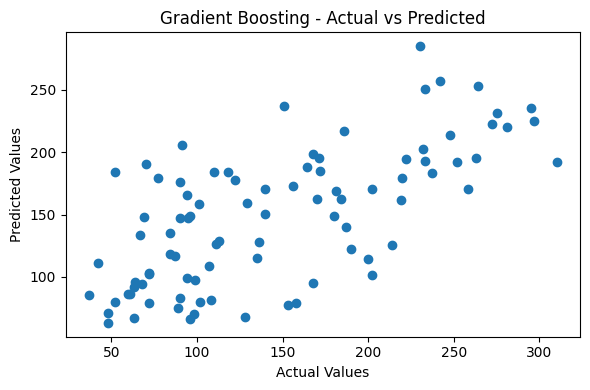

In [19]:
plt.figure(figsize=(6, 4))

plt.scatter(
    yd_test,
    y_pred_diabetes
)

plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title("Gradient Boosting - Actual vs Predicted")

plt.tight_layout()
plt.show()

In [20]:
comparison = pd.DataFrame([
    {
        "Model": "Decision Tree",
        "Dataset": "Breast Cancer",
        "Task": "Classification",
        "Accuracy": round(dt_accuracy, 4),
        "Precision": round(dt_precision, 4),
        "Recall": round(dt_recall, 4),
        "F1-Score": round(dt_f1, 4),
        "MAE": "-",
        "MSE": "-",
        "R2 Score": "-"
    },
    {
        "Model": "Random Forest",
        "Dataset": "Wine",
        "Task": "Classification",
        "Accuracy": round(rf_accuracy, 4),
        "Precision": round(rf_precision, 4),
        "Recall": round(rf_recall, 4),
        "F1-Score": round(rf_f1, 4),
        "MAE": "-",
        "MSE": "-",
        "R2 Score": "-"
    },
    {
        "Model": "Gradient Boosting",
        "Dataset": "Diabetes",
        "Task": "Regression",
        "Accuracy": "-",
        "Precision": "-",
        "Recall": "-",
        "F1-Score": "-",
        "MAE": round(gb_mae, 4),
        "MSE": round(gb_mse, 4),
        "R2 Score": round(gb_r2, 4)
    }
])

display(comparison)

,Model,Dataset,Task,Accuracy,Precision,Recall,F1-Score,MAE,MSE,R2 Score
0,Decision Tree,Breast Cancer,Classification,0.9123,0.9161,0.9123,0.913,-,-,-
1,Random Forest,Wine,Classification,1.0,1.0,1.0,1.0,-,-,-
2,Gradient Boosting,Diabetes,Regression,-,-,-,-,44.6033,2898.4367,0.4529


Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.
